# Disease Prediction from Medical Data Using Machine Learning

> ⚠️ **Educational project only.** This notebook is a learning exercise. It is **not** a medical diagnostic system and must never be used to make health decisions.

## 1. Introduction and Objective
We build and compare supervised **classification** models that predict whether a breast tumour is **malignant** (the "disease" class) or **benign**, using numeric measurements taken from digitised images of cell nuclei.

**Goals**
1. Explore and check the quality of a public medical dataset.
2. Train four algorithms: Logistic Regression, SVM, Random Forest and XGBoost.
3. Evaluate with accuracy, precision, recall, F1, ROC-AUC and confusion matrices.
4. Discuss why, in medicine, *missing a sick patient* (false negative) is usually worse than a false alarm (false positive).

## 2. Dataset Description and Source
**Breast Cancer Wisconsin (Diagnostic) Dataset** — Wolberg, Street & Mangasarian, UCI Machine Learning Repository (DOI: 10.24432/C5DW2B). Original page: <https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic>. Licence: CC BY 4.0.

**Why this dataset?** It is clean, small (569 rows), fully numeric, has a clear binary target, and contains **no personal patient information** — ideal for a beginner-friendly project.

- **Target:** `diagnosis` — `M` = malignant (disease), `B` = benign.
- **Features:** 30 numeric columns = 10 measurements (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension) × 3 statistics (`mean_`, `_error` = standard error, `worst_` = largest value).
- **Numerical features:** all 30. **Categorical features:** none (only the target is categorical).

The CSV in `data/` was exported from the copy of the dataset bundled with scikit-learn (the sandbox used to build this project could not reach the UCI website). See `data/DATA_SOURCE.md` for details.

## 3. Import Libraries

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42  # fixed seed -> reproducible results

## 4. Load the Dataset
The notebook finds the project root automatically, so no hard-coded local paths are needed (works whether you launch Jupyter from the root or from `notebooks/`).

In [2]:
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA_PATH = ROOT / "data" / "disease_dataset.csv"
IMAGES_DIR = ROOT / "images"
IMAGES_DIR.mkdir(exist_ok=True)

df = pd.read_csv(DATA_PATH)
print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (569, 31)


,diagnosis,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,mean_compactness,mean_concavity,mean_concave_points,mean_symmetry,...,worst_radius,worst_texture,worst_perimeter,worst_area,worst_smoothness,worst_compactness,worst_concavity,worst_concave_points,worst_symmetry,worst_fractal_dimension
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## 5. Initial Data Exploration

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   diagnosis                569 non-null    str    
 1   mean_radius              569 non-null    float64
 2   mean_texture             569 non-null    float64
 3   mean_perimeter           569 non-null    float64
 4   mean_area                569 non-null    float64
 5   mean_smoothness          569 non-null    float64
 6   mean_compactness         569 non-null    float64
 7   mean_concavity           569 non-null    float64
 8   mean_concave_points      569 non-null    float64
 9   mean_symmetry            569 non-null    float64
 10  mean_fractal_dimension   569 non-null    float64
 11  radius_error             569 non-null    float64
 12  texture_error            569 non-null    float64
 13  perimeter_error          569 non-null    float64
 14  area_error               569 non-null

In [4]:
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
mean_radius,569.0,14.127,3.524,6.981,11.700,13.370,15.780,28.110
mean_texture,569.0,19.290,4.301,9.710,16.170,18.840,21.800,39.280
mean_perimeter,569.0,91.969,24.299,43.790,75.170,86.240,104.100,188.500
mean_area,569.0,654.889,351.914,143.500,420.300,551.100,782.700,2501.000
mean_smoothness,569.0,0.096,0.014,0.053,0.086,0.096,0.105,0.163
mean_compactness,569.0,0.104,0.053,0.019,0.065,0.093,0.130,0.345
mean_concavity,569.0,0.089,0.080,0.000,0.030,0.062,0.131,0.427
mean_concave_points,569.0,0.049,0.039,0.000,0.020,0.034,0.074,0.201
mean_symmetry,569.0,0.181,0.027,0.106,0.162,0.179,0.196,0.304
mean_fractal_dimension,569.0,0.063,0.007,0.050,0.058,0.062,0.066,0.097


## 6. Data Cleaning and Preprocessing
Quality checks: **missing values, duplicates, invalid values, class imbalance**.

In [5]:
print("Missing values (total):", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

features = [c for c in df.columns if c != "diagnosis"]
print("Features that are not numeric:", [c for c in features if not pd.api.types.is_numeric_dtype(df[c])])
# Invalid values: these measurements cannot be negative, and radius/area/perimeter cannot be zero
print("Negative values:", int((df[features] < 0).sum().sum()))
print("Zero radius/area/perimeter rows:", int((df[["mean_radius", "mean_area", "mean_perimeter"]] == 0).any(axis=1).sum()))
print("\nClass counts:\n", df["diagnosis"].value_counts())
print("\nClass share (%):\n", (df["diagnosis"].value_counts(normalize=True) * 100).round(1))

Missing values (total): 0
Duplicate rows: 0
Features that are not numeric: []
Negative values: 0
Zero radius/area/perimeter rows: 0

Class counts:
 diagnosis
B    357
M    212
Name: count, dtype: int64

Class share (%):
 diagnosis
B    62.7
M    37.3
Name: proportion, dtype: float64


**What we found:** no missing values, duplicates or invalid values, and a moderate class imbalance (about 63% benign / 37% malignant). Because of this imbalance we use a **stratified** split (keeps the same proportions in train and test) and look at recall/F1 rather than accuracy alone.

Even though nothing is missing, we still include a median **imputer** in the pipeline so the code stays robust to future data. We encode the target as `1 = malignant (disease)`, `0 = benign`. Scaling is applied inside the pipelines (only for scale-sensitive models), which avoids **data leakage**.

In [6]:
X = df.drop(columns=["diagnosis"])
y = (df["diagnosis"] == "M").astype(int)   # 1 = malignant (disease), 0 = benign

## 7. Exploratory Data Analysis

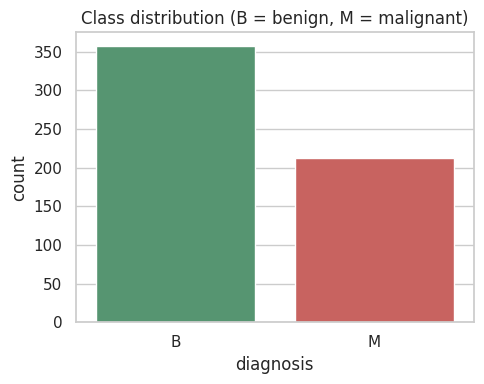

In [7]:
fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(x="diagnosis", data=df, order=["B", "M"], palette=["#4c9f70", "#d9534f"], ax=ax)
ax.set_title("Class distribution (B = benign, M = malignant)")
plt.tight_layout(); plt.savefig(IMAGES_DIR / "class_distribution.png", dpi=120); plt.show()

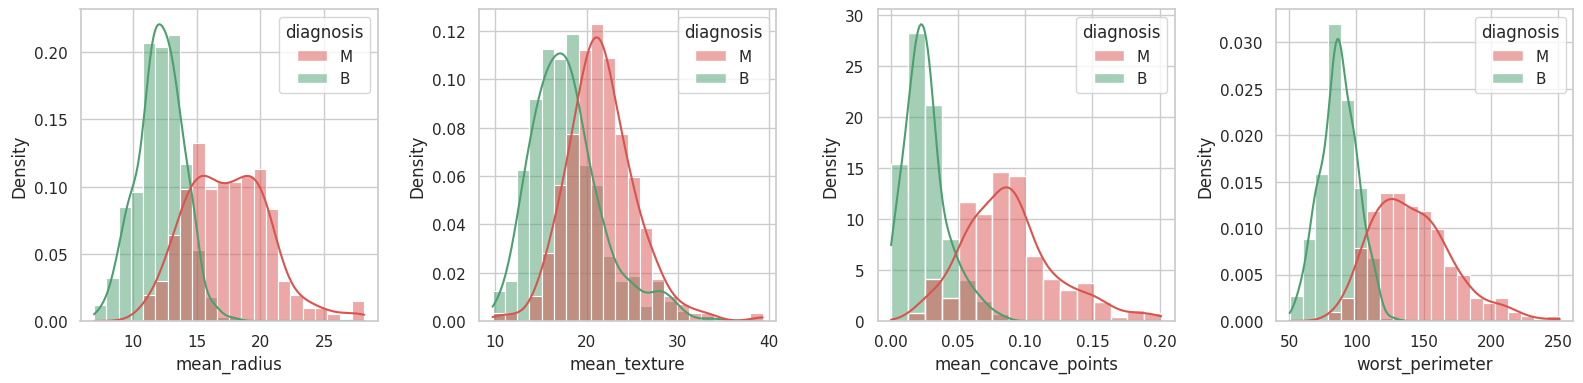

In [8]:
# Distribution of a few key features by diagnosis
key = ["mean_radius", "mean_texture", "mean_concave_points", "worst_perimeter"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, key):
    sns.histplot(data=df, x=col, hue="diagnosis", kde=True, stat="density", common_norm=False,
                 palette={"B": "#4c9f70", "M": "#d9534f"}, ax=ax)
plt.tight_layout(); plt.savefig(IMAGES_DIR / "feature_distributions.png", dpi=120); plt.show()

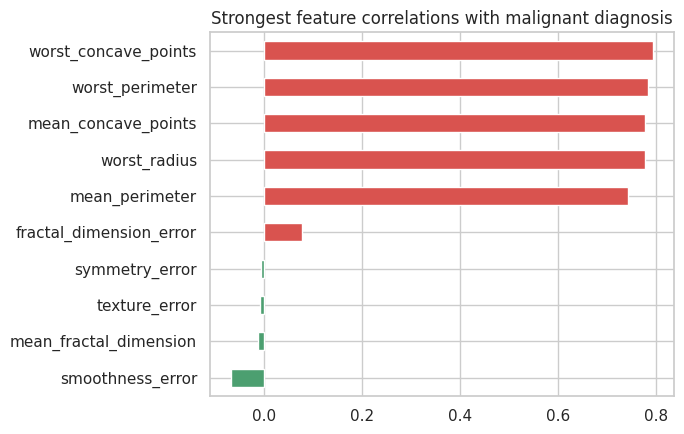

In [9]:
# Correlation of each feature with the target (malignant = 1)
corr = X.corrwith(y).sort_values()
top = pd.concat([corr.head(5), corr.tail(5)])
fig, ax = plt.subplots(figsize=(7, 4.5))
top.plot(kind="barh", color=["#4c9f70" if v < 0 else "#d9534f" for v in top], ax=ax)
ax.set_title("Strongest feature correlations with malignant diagnosis")
plt.tight_layout(); plt.savefig(IMAGES_DIR / "target_correlations.png", dpi=120); plt.show()

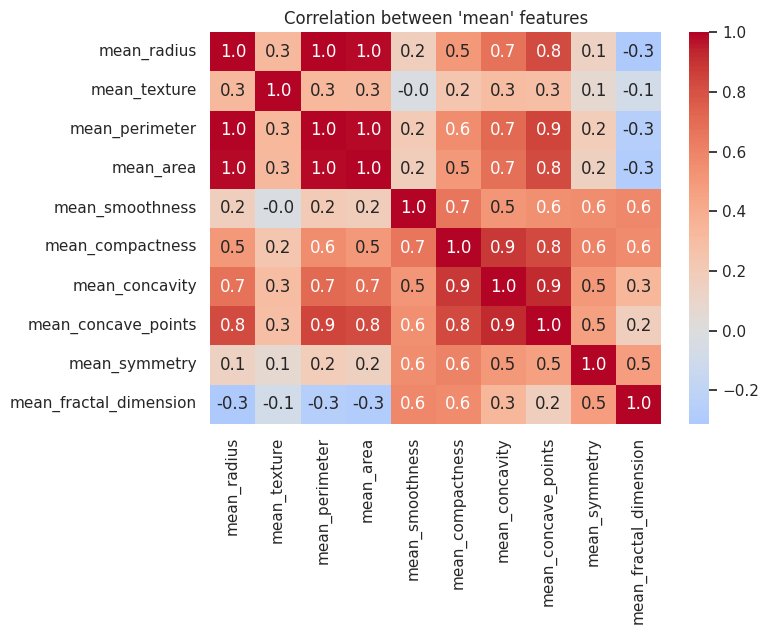

In [10]:
# Heatmap of the 10 'mean_' features: many are strongly correlated with each other
mean_cols = [c for c in X.columns if c.startswith("mean_")]
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(X[mean_cols].corr(), annot=True, fmt=".1f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation between 'mean' features")
plt.tight_layout(); plt.savefig(IMAGES_DIR / "correlation_heatmap.png", dpi=120); plt.show()

**EDA takeaways:** malignant tumours tend to have larger radius, perimeter and more concave points. Several features (radius, perimeter, area) are almost duplicates of each other (very high correlation). This is fine for the models used here, but it makes individual coefficients harder to interpret.

## 8. Train-Test Split
80% of the data is used for training, 20% is held out for final testing. `stratify=y` keeps the class ratio equal in both sets.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Malignant share - train: %.3f, test: %.3f" % (y_train.mean(), y_test.mean()))

Train: (455, 30) | Test: (114, 30)
Malignant share - train: 0.374, test: 0.368


## 9. Model Training
We compare four algorithms. Each is wrapped in a `Pipeline` with a `ColumnTransformer` so imputation and scaling are learned **only from the training data**.

| Model | Scaling? | Why |
|---|---|---|
| Logistic Regression | Yes | Simple, fast, interpretable baseline |
| SVM (RBF kernel) | Yes | Handles non-linear boundaries; needs scaling |
| Random Forest | No | Ensemble of trees; robust, scale-free |
| XGBoost | No | Gradient-boosted trees; often very strong on tabular data |

We also run 5-fold stratified **cross-validation on the training set only** — this gives a more stable estimate than one split and lets us choose a model without peeking at the test set.

In [12]:
num_cols = X.columns.tolist()

def make_preprocessor(scale):
    steps = [("impute", SimpleImputer(strategy="median"))]
    if scale:
        steps.append(("scale", StandardScaler()))
    return ColumnTransformer([("num", Pipeline(steps), num_cols)])

models = {
    "Logistic Regression": Pipeline([("prep", make_preprocessor(True)),
                                     ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))]),
    "SVM (RBF)": Pipeline([("prep", make_preprocessor(True)),
                           ("clf", SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE))]),
    "Random Forest": Pipeline([("prep", make_preprocessor(False)),
                               ("clf", RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE))]),
    "XGBoost": Pipeline([("prep", make_preprocessor(False)),
                         ("clf", XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.1,
                                               eval_metric="logloss", random_state=RANDOM_STATE))]),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_results = {}
for name, pipe in models.items():
    cv_results[name] = cross_validate(pipe, X_train, y_train, cv=cv, scoring=["recall", "f1"])
    pipe.fit(X_train, y_train)          # final fit on the full training set
    print(f"Trained: {name}")

Trained: Logistic Regression


Trained: SVM (RBF)


Trained: Random Forest


Trained: XGBoost


## 10. Model Evaluation
Metrics (positive class = malignant):
- **Accuracy** – share of all predictions that are correct.
- **Precision** – of patients flagged malignant, how many truly are.
- **Recall (sensitivity)** – of truly malignant patients, how many we caught.
- **F1** – balance of precision and recall.
- **ROC-AUC** – how well the model ranks malignant above benign across all thresholds.

In [13]:
rows, preds, probas = [], {}, {}
for name, pipe in models.items():
    preds[name] = pipe.predict(X_test)
    probas[name] = pipe.predict_proba(X_test)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, preds[name]).ravel()
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, preds[name]),
        "Precision": precision_score(y_test, preds[name]),
        "Recall": recall_score(y_test, preds[name]),
        "F1": f1_score(y_test, preds[name]),
        "ROC_AUC": roc_auc_score(y_test, probas[name]),
        "False_Negatives": int(fn), "False_Positives": int(fp),
        "CV_Recall_Mean": cv_results[name]["test_recall"].mean(),
        "CV_F1_Mean": cv_results[name]["test_f1"].mean(),
    })
results = (pd.DataFrame(rows).round(4)
           .sort_values(["CV_Recall_Mean", "CV_F1_Mean"], ascending=False).reset_index(drop=True))
results

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,False_Negatives,False_Positives,CV_Recall_Mean,CV_F1_Mean
0,Logistic Regression,0.9649,0.975,0.9286,0.9512,0.9960,3,1,0.9529,0.9640
1,XGBoost,0.9561,1.000,0.8810,0.9367,0.9937,5,0,0.9529,0.9614
2,SVM (RBF),0.9737,1.000,0.9286,0.9630,0.9947,3,0,0.9471,0.9610
3,Random Forest,0.9737,1.000,0.9286,0.9630,0.9944,3,0,0.9353,0.9461


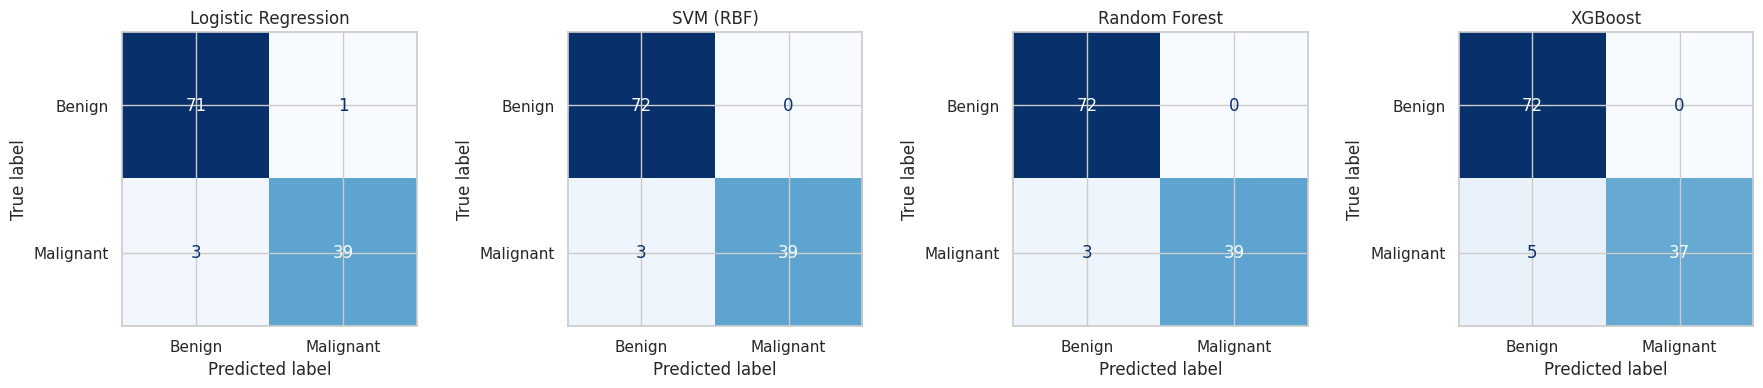

In [14]:
# Confusion matrices on the test set
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, name in zip(axes, models):
    ConfusionMatrixDisplay.from_predictions(y_test, preds[name], display_labels=["Benign", "Malignant"],
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(name)
plt.tight_layout(); plt.savefig(IMAGES_DIR / "confusion_matrices.png", dpi=120); plt.show()

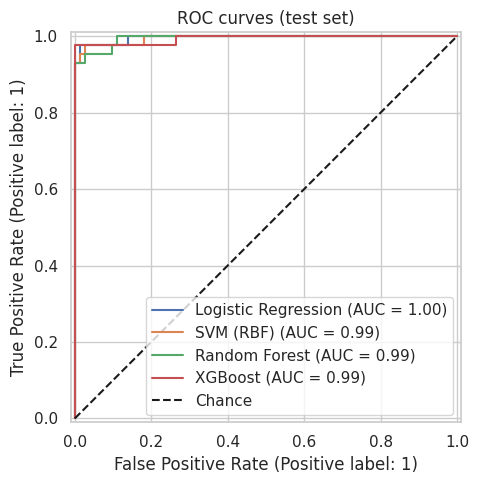

In [15]:
# ROC curves
fig, ax = plt.subplots(figsize=(6, 5))
for name in models:
    RocCurveDisplay.from_predictions(y_test, probas[name], name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Chance")
ax.set_title("ROC curves (test set)"); ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig(IMAGES_DIR / "roc_curves.png", dpi=120); plt.show()

## 11. Performance Comparison

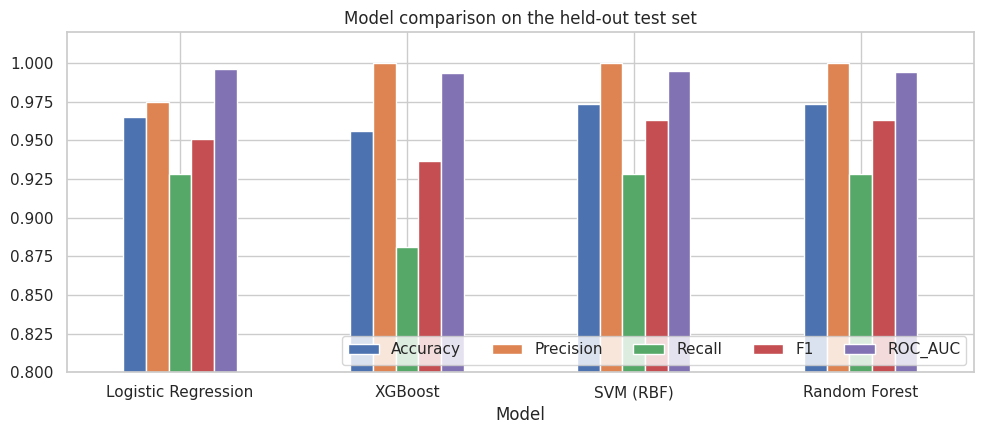

In [16]:
metrics = ["Accuracy", "Precision", "Recall", "F1", "ROC_AUC"]
ax = results.set_index("Model")[metrics].plot(kind="bar", figsize=(10, 4.5), rot=0, ylim=(0.8, 1.02))
ax.set_title("Model comparison on the held-out test set"); ax.legend(loc="lower right", ncol=5)
plt.tight_layout(); plt.savefig(IMAGES_DIR / "model_comparison.png", dpi=120); plt.show()

In [17]:
# Which model do we pick? Selection uses CROSS-VALIDATION on training data (not the test set),
# prioritising recall and then F1 - NOT accuracy alone.
best_name = results.loc[0, "Model"]
print("Selected model:", best_name)

# Consistency check with the command-line script's saved results
saved = ROOT / "reports" / "model_comparison.csv"
if saved.exists():
    ref = pd.read_csv(saved)
    same = np.allclose(ref.set_index("Model").sort_index().drop(columns=[]).to_numpy(),
                       results.set_index("Model").sort_index().to_numpy(), atol=1e-3)
    print("Matches reports/model_comparison.csv from src/train_model.py:", same)

Selected model: Logistic Regression
Matches reports/model_comparison.csv from src/train_model.py: True


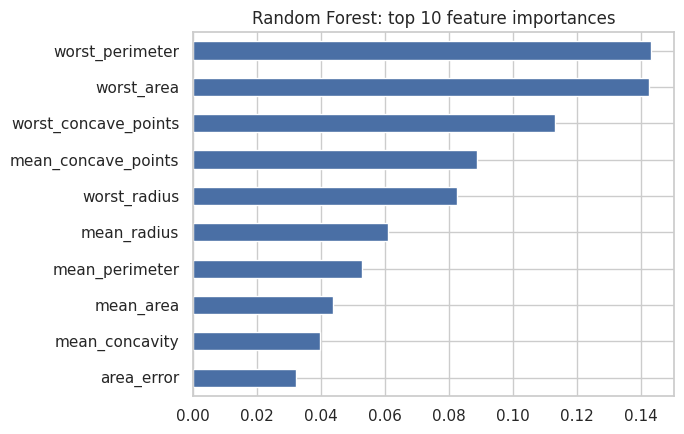

In [18]:
# Which features matter most for Random Forest? (interpretation aid, not clinical evidence)
rf = models["Random Forest"].named_steps["clf"]
imp = pd.Series(rf.feature_importances_, index=num_cols).sort_values().tail(10)
fig, ax = plt.subplots(figsize=(7, 4.5))
imp.plot(kind="barh", color="#4a6fa5", ax=ax); ax.set_title("Random Forest: top 10 feature importances")
plt.tight_layout(); plt.savefig(IMAGES_DIR / "feature_importance.png", dpi=120); plt.show()

## 12. Final Findings and Limitations
See the results table above for the exact numbers. In plain language:

- **All four models perform well** on this clean dataset, with ROC-AUC values around 0.99 — the classes are quite separable.
- **Accuracy hides the real story.** Several models have the same or similar accuracy but miss a different number of malignant cases. The `False_Negatives` column shows how many malignant tumours each model labelled benign.
- **Why recall matters:** a **false negative** (a sick patient told "benign") can delay treatment, while a **false positive** usually leads to extra tests. So in a medical screening setting we care a lot about recall — while still keeping precision reasonable.
- **Close call:** the top models are separated by very small differences in cross-validated recall. With only 114 test rows (42 malignant), one or two patients change the metrics noticeably, so the ranking should not be treated as definitive.
- Models with perfect precision (no false positives) here still missed some malignant cases; none of the models reached 100% recall.

**Limitations**
- Small dataset (569 samples) from a single source; no external validation.
- Features come from already-extracted image measurements, not raw images or full clinical history.
- Default-ish hyperparameters; no extensive tuning was done.
- Decision threshold left at 0.5; a lower threshold would raise recall at the cost of precision.
- Not clinically validated, not calibrated for real-world prevalence, and not fairness-audited. **Do not use for real medical decisions.**

## 13. How to Run This Project
```bash
# 1. Create and activate a virtual environment (recommended)
python -m venv .venv
source .venv/bin/activate        # Windows: .venv\Scripts\activate

# 2. Install dependencies
pip install -r requirements.txt

# 3. Launch Jupyter from the project root
jupyter notebook notebooks/disease_prediction.ipynb

# Optional: run the command-line script
python src/train_model.py
```
Then choose **Kernel → Restart & Run All**.